# NHL: предсказать успешность команды в следующем сезоне

**Тестовое задание • 100 баллов**

Вы аналитик, которому после окончания сезона нужно оценить перспективы команды
на следующий год. Соберите таблицу с учебного сайта
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/),
изучите данные и постройте модель классификации.
В работе оцениваются корректность исследования и обоснованность решений.

Ориентир времени: 6-10 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами и исходный `data/hockey_raw.csv` разместите на платформе githib.com.
Укажите имя, дату и использованные источники и инструменты в README.

## Что предсказывает модель

Одна строка признаков описывает команду в сезоне `t`.
`target=1`, если доля побед той же команды в сезоне `t+1` строго выше медианной
доли побед всех команд в сезоне `t+1`. В остальных случаях `target=0`.

Медиану считайте по полной исходной таблице будущего года до отбора пар.
В пары включайте одинаковые названия команды с разницей меток сезонов ровно в один год.
Строки без пары исключайте и учитывайте в описании данных.
Будущий `win_rate` и будущая медиана используются для построения target и анализа
готовых прогнозов. Признаки модели должны быть известны после сезона `t`.

## Схема проверки

Делите данные по году целевого сезона:

| Часть | target_year | Назначение |
|---|---|---|
| train | не позднее 2005 | Подготовка данных и обучение |
| validation | 2006-2008 | Сравнение вариантов и выбор решения |
| test | 2009-2011 | Одна итоговая оценка выбранного решения |

Основная метрика: ROC-AUC по вероятности класса 1.
На итоговом этапе также используйте F1 и accuracy при пороге 0.5.
Финальный test используйте после выбора решения на validation.

## Как оценивается работа

| Область | Баллы |
|---|---:|
| Сбор и понимание данных | 15 |
| Построение задачи и корректность проверки | 20 |
| Исследовательский анализ | 20 |
| Модели и эксперименты | 25 |
| Итоговая оценка и анализ ошибок | 15 |
| Ясность и воспроизводимость | 5 |
| **Всего** | **100** |

Ниже перечислены обязательные этапы работы. Внутри них вы самостоятельно выбираете
исследовательские вопросы, графики, признаки, обработку данных, эксперимент и способ
разбора ошибок. Оценивается качество решений, а не совпадение с эталонным маршрутом.
Сложность метода сама по себе не даёт преимущества. Корректный эксперимент может
получить полный балл и в случае отсутствия улучшения.

## Требования к сбору

Итоговая исходная таблица должна иметь столбцы `team`, `year`, `wins`, `losses`,
`ot_losses`, `win_rate`, `goals_for`, `goals_against`, `goal_diff`.
Самостоятельно исследуйте страницу и определите способ получения всей таблицы.

**Автор:** Филатова Арина

**Дата:** 12.10.2026

**Использованные источники и инструменты:** …

In [1]:
%pip install -q "requests" "pandas" "beautifulsoup4" "seaborn"

In [76]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
import os
from datetime import datetime
import numpy as np

## Раздел 1. Сбор и понимание данных: 15 баллов

### 1.1. Соберите и сохраните данные

Соберите все страницы сайта в одну таблицу с указанными девятью столбцами.
Сохраните исходную выгрузку в `data/hockey_raw.csv`. Укажите URL и дату сбора,
число обработанных страниц и число строк. Покажите, как проверили,
что сбор не ограничился первой страницей и при повторном анализе можно читать CSV.

In [13]:
# 1.1. Ваш код
# Добавьте ячейки при необходимости.
url = "https://www.scrapethissite.com/pages/forms/"

all_data = []
page_num = 1
seen_pages = set()

while True:
    params = {"page_num": page_num}
    response = requests.get(url, params=params, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    table = soup.find("table")
    if table is None:
        break

    rows = table.find_all("tr")[1:]
    page_content = tuple(row.get_text(" ", strip = True) for row in rows)

    if page_content in seen_pages:
      print("Страница повторилась. Останавливаем сбор.")
      break
    seen_pages.add(page_content)
    if len(rows) == 0:
        break
    for row in rows:
        cells = row.find_all("td")
        values = [cell.get_text(strip=True) for cell in cells]
        all_data.append(values)

    page_num += 1

columns = [ "team", "year", "wins", "losses", "ot_losses",
            "win_rate", "goals_for", "goals_against", "goal_diff" ]
df = pd.DataFrame(all_data, columns=columns)


os.makedirs("data", exist_ok=True)
df.to_csv("data/hockey_raw.csv", index=False)
#df_check = pd.read_csv("data/hockey_raw.csv")
#print(df_check.shape)

print("Источник:", url)
print("Дата сбора:", datetime.now().strftime("%Y-%m-%d"))
print("Обработано страниц:", len(seen_pages))
print("Количество строк:", len(df))
print("Количество столбцов:", len(df.columns))


Источник: https://www.scrapethissite.com/pages/forms/
Дата сбора: 2026-10-13
Обработано страниц: 25
Количество строк: 582
Количество столбцов: 9


**Ответ 1.1:**

_Ваш ответ со ссылками на результаты собственной работы._

### 1.2. Проверьте качество таблицы

Изучите типы, пропуски и уникальность пары команда-год.
Добавьте не менее двух проверок согласованности, которые считаете важными
для последующего анализа. Покажите найденные особенности и обоснуйте
решения по их обработке. Сами проверки и способ представления результата выберите самостоятельно.

In [33]:
# 1.2. Ваш код
# Добавьте ячейки при необходимости.
df.info()
df.isna().sum()
duplicates = df.duplicated(subset=["team", "year"])
print(f"\nКоличество дубликатов: {duplicates.sum()}\n")

df_clean = df.copy()
numeric_columns = [ "year", "wins", "losses", "ot_losses",
    "win_rate", "goals_for", "goals_against", "goal_diff"]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
display(df_clean[numeric_columns].isna().sum())

wrong_goals = df_clean[
    df_clean["goal_diff"] != (df_clean["goals_for"] - df_clean["goals_against"])]
print(f"\nСтрок с неверной разницей голов: {len(wrong_goals)}\n")

games = (df_clean["wins"] + df_clean["losses"] + df_clean["ot_losses"].fillna(0))
df_clean["calculated_win_rate"] = df_clean["wins"] / games
df_clean["win_rate_diff"] = (df_clean["win_rate"] - df_clean["calculated_win_rate"]).abs()
#display(df_clean[["team", "year", "win_rate","calculated_win_rate", "win_rate_diff"]].head(10))

wrong_win_rate = df_clean[df_clean["win_rate_diff"] > 0.01]
print("Количество расхождений win_rate:", len(wrong_win_rate))
#display(wrong_win_rate[["team", "year", "win_rate", "calculated_win_rate"]].head(10))
wrong_win_rate.groupby("year").size()

example = df_clean[(df_clean["win_rate"] > 0) &(df_clean["win_rate_diff"] > 0.01)].copy()
example["estimated_games"] = (example["wins"] / example["win_rate"])
display(example[["team", "year", "wins", "losses","ot_losses", "estimated_games"]].head(10)) #Восстановление риблизительного колва игр




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   team           582 non-null    object
 1   year           582 non-null    object
 2   wins           582 non-null    object
 3   losses         582 non-null    object
 4   ot_losses      582 non-null    object
 5   win_rate       582 non-null    object
 6   goals_for      582 non-null    object
 7   goals_against  582 non-null    object
 8   goal_diff      582 non-null    object
dtypes: object(9)
memory usage: 41.1+ KB

Количество дубликатов: 0



,0
year,0
wins,0
losses,0
ot_losses,224
win_rate,0
goals_for,0
goals_against,0
goal_diff,0



Строк с неверной разницей голов: 0

Количество расхождений win_rate: 370


,team,year,wins,losses,ot_losses,estimated_games
0,Boston Bruins,1990,44,24,NaN,80.000000
1,Buffalo Sabres,1990,31,30,NaN,79.896907
2,Calgary Flames,1990,46,26,NaN,80.000000
3,Chicago Blackhawks,1990,49,23,NaN,79.934747
4,Detroit Red Wings,1990,34,38,NaN,80.000000
5,Edmonton Oilers,1990,37,37,NaN,79.913607
6,Hartford Whalers,1990,31,38,NaN,79.896907
7,Los Angeles Kings,1990,46,24,NaN,80.000000
8,Minnesota North Stars,1990,27,39,NaN,79.881657
9,Montreal Canadiens,1990,39,30,NaN,80.082136


**Ответ 1.2:**

_Ваш ответ со ссылками на результаты собственной работы._

## Раздел 2. Построение задачи и корректность проверки: 20 баллов

### 2.1. Постройте target

Соедините строку команды в сезоне `t` с той же командой ровно в сезоне `t+1`
и постройте target по определению задания. Покажите число полученных пар,
число и годы исключённых строк, а также число случаев равенства будущей медиане.
Проверьте расчёт вручную минимум на двух содержательно разных примерах.

In [56]:
# 2.1. Ваш код
# Добавьте ячейки при необходимости.
year_medians = df_clean.groupby("year")["win_rate"].median()

future = df_clean[["team", "year", "win_rate"]].copy() #Табл о след сезоне команды
future = future.rename(columns={"year": "target_year","win_rate": "future_win_rate"})

current = df_clean.copy()
current["target_year"] = current["year"] + 1

pairs = current.merge(future, on=["team", "target_year"], how="inner",validate="one_to_one")
pairs["future_median"] = pairs["target_year"].map(year_medians)
assert pairs[["future_win_rate", "future_median"]].notna().all().all(), ("Обнаружены пропуски в данных для target")
pairs["target"] = (pairs["future_win_rate"] > pairs["future_median"]).astype(int)
#display(pairs[["team", "target_year", "future_win_rate", "future_median", "target"]].head(10))

equal_median = pairs[pairs["future_win_rate"] == pairs["future_median"]]
excluded_count = len(df_clean) - len(pairs)
excluded = current.merge(
    future[["team", "target_year"]],
    on=["team", "target_year"],
    how="left",
    indicator=True
)
excluded = excluded[excluded["_merge"] == "left_only"]


print("Строк в исходной таблице:", len(df_clean))
print("Получилось пар сезонов:", len(pairs))
print("Исключено строк:", excluded_count)
print(f"\nВ каких годах искл строки:\n{excluded.groupby('year').size()}")
print("\nРаспределение target:")
print(pairs["target"].value_counts().sort_index())
print("\nСлучаев равенства медиане:", len(equal_median))
print("\nПример полученной таблицы:")
display(pairs[["team", "year", "target_year", "win_rate","future_win_rate", "future_median", "target"]].head(10))


#ПРОВЕРКА расчета двух команд
example_1 = pairs[pairs["target"] == 1].iloc[0]
example_0 = pairs[pairs["target"] == 0].iloc[0]

for example in [example_1, example_0]:
    print(f"\nКоманда: {example['team']}")
    print(f"Текущий сезон: {example['year']}")
    print(f"Будущий сезон: {example['target_year']}")
    print(f"Доля побед: {example['future_win_rate']}")
    print(f"Медиана лиги: {example['future_median']}")
    print(f"Target: {example['target']}")


Строк в исходной таблице: 582
Получилось пар сезонов: 516
Исключено строк: 66

В каких годах искл строки:
year
1992     1
1994     1
1995     1
1996     1
2003    30
2005     1
2010     1
2011    30
dtype: int64

Распределение target:
target
0    266
1    250
Name: count, dtype: int64

Случаев равенства медиане: 23

Пример полученной таблицы:


,team,year,target_year,win_rate,future_win_rate,future_median,target
0,Boston Bruins,1990,1991,0.550,0.450,0.444,1
1,Buffalo Sabres,1990,1991,0.388,0.388,0.444,0
2,Calgary Flames,1990,1991,0.575,0.388,0.444,0
3,Chicago Blackhawks,1990,1991,0.613,0.450,0.444,1
4,Detroit Red Wings,1990,1991,0.425,0.537,0.444,1
5,Edmonton Oilers,1990,1991,0.463,0.450,0.444,1
6,Hartford Whalers,1990,1991,0.388,0.325,0.444,0
7,Los Angeles Kings,1990,1991,0.575,0.438,0.444,0
8,Minnesota North Stars,1990,1991,0.338,0.400,0.444,0
9,Montreal Canadiens,1990,1991,0.487,0.512,0.444,1



Команда: Boston Bruins
Текущий сезон: 1990
Будущий сезон: 1991
Доля побед: 0.45
Медиана лиги: 0.444
Target: 1

Команда: Buffalo Sabres
Текущий сезон: 1990
Будущий сезон: 1991
Доля побед: 0.388
Медиана лиги: 0.444
Target: 0


**Ответ 2.1:**

_Ваш ответ со ссылками на результаты собственной работы._

### 2.2. Подготовьте временную проверку

Разделите пары на train, validation и test по заданным границам target_year.
Покажите для каждой части фактические годы, размер и долю класса 1.
Назовите минимум два столбца, которые появились при построении target,
но недоступны модели в момент прогноза. Объясните, почему случайное перемешивание
строк отвечало бы на другой вопрос, чем выбранная временная схема.

In [61]:
# 2.2. Ваш код
# Добавьте ячейки при необходимости.
train = pairs[pairs["target_year"] <= 2005].copy()
val = pairs[(pairs["target_year"] >= 2006) & (pairs["target_year"] <= 2008)].copy()
test = pairs[(pairs["target_year"] >= 2009) & (pairs["target_year"] <= 2011)].copy()

for name, dataset in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)]:

    print(f"\n{name}")
    print("Годы:", sorted(dataset["target_year"].unique()))
    print("Количество строк:", len(dataset))
    print("Доля класса 1:", dataset["target"].mean())

#проверка на отстутсвтие пересечений
assert train["target_year"].max() <= 2005
assert val["target_year"].between(2006, 2008).all()
assert test["target_year"].between(2009, 2011).all()
print("Временные границы соблюдены!")

print("Исходных пар:", len(pairs))
print("После разделения:", len(train) + len(val) + len(test))



Train
Годы: [np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003)]
Количество строк: 338
Доля класса 1: 0.4911242603550296
Временные границы соблюдены!
Исходных пар: 516
После разделения: 516

Validation
Годы: [np.int64(2006), np.int64(2007), np.int64(2008)]
Количество строк: 89
Доля класса 1: 0.47191011235955055
Временные границы соблюдены!
Исходных пар: 516
После разделения: 516

Test
Годы: [np.int64(2009), np.int64(2010), np.int64(2011)]
Количество строк: 89
Доля класса 1: 0.47191011235955055
Временные границы соблюдены!
Исходных пар: 516
После разделения: 516


**Ответ 2.2:**

_Ваш ответ со ссылками на результаты собственной работы._

## Раздел 3. Исследовательский анализ: 20 баллов

### 3.1. Сформулируйте вопросы к данным

До построения основных графиков сформулируйте не менее двух собственных
исследовательских вопросов, связанных с будущей успешностью команд
или устройством данных. Для каждого запишите ожидаемый результат и объясните,
как ответ может повлиять на выбор признаков, обработку или интерпретацию модели.

### Исследовательский вопрос 1

**Помогает ли высокая доля побед команды в текущем сезоне прогнозировать её успешность в следующем сезоне?**

**Гипотеза:** Предполагается, что команды с более высокой долей побед (`win_rate`) в текущем сезоне чаще будут иметь `target = 1` в следующем сезоне.

**Ожидаемый результат:** Доля успешных команд должна увеличиваться с ростом `win_rate`.

**Практическое значение:** Если гипотеза подтвердится, `win_rate` можно рассматривать как потенциально полезный признак для модели прогнозирования. Если связь окажется слабой, это будет означать, что одного показателя доли побед недостаточно для уверенного прогноза.

### Исследовательский вопрос 2

**Связана ли разница забитых и пропущенных голов команды с её успешностью в следующем сезоне?**

**Гипотеза:** Команды с положительной и более высокой разницей голов (`goal_diff`) чаще будут иметь `target = 1` в следующем сезоне.

**Ожидаемый результат:** По мере увеличения `goal_diff` доля успешных команд должна возрастать.

**Практическое значение:** Если гипотеза подтвердится, разницу голов можно будет рассматривать как дополнительный признак модели. Также будет полезно сравнить её информативность с `win_rate`, поскольку оба показателя характеризуют силу команды, но с разных сторон.

,count,mean,median,std
target,,,,
0,172,0.386872,0.3915,0.094205
1,166,0.485006,0.4875,0.086897


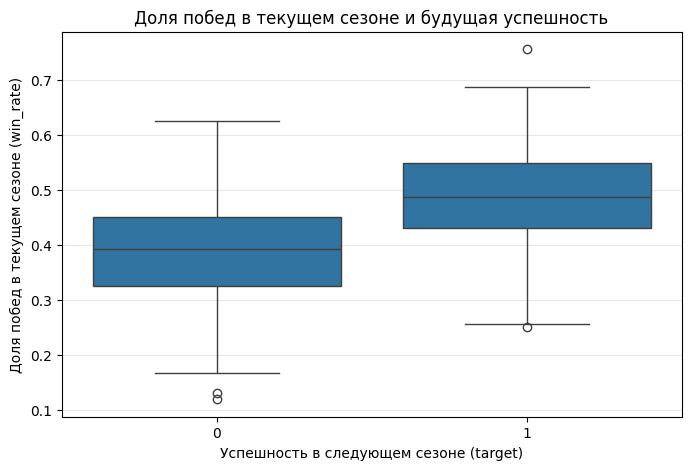

In [64]:
# 3.1. Ваш код
# Добавьте ячейки при необходимости.

### 3.2. Проведите исследовательский анализ

Ответьте на вопросы из пункта 3.1 с помощью числовых сводок и визуализаций.
Количество и типы графиков выберите сами: их должно быть достаточно,
чтобы подтвердить выводы, а каждый график должен отвечать на сформулированный вопрос.
Покажите хотя бы одно конкретное наблюдение на уровне команды или сезона.
Для каждого вывода укажите ограничение интерпретации.

Размер обучающей выборки: (338, 15)


,count,mean,median,std
target,,,,
0,172,0.386872,0.3915,0.094205
1,166,0.485006,0.4875,0.086897


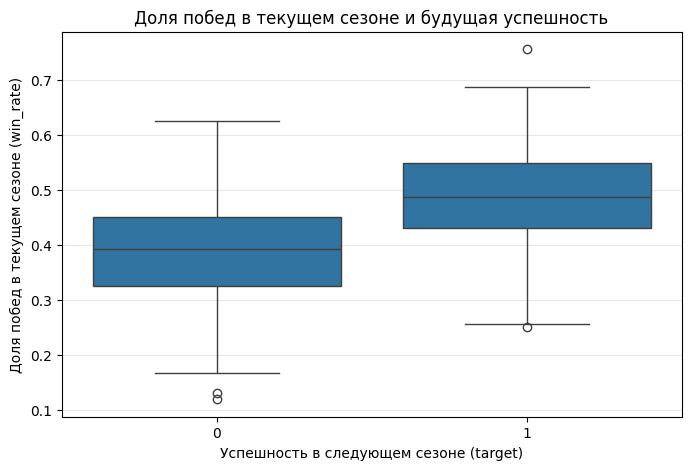


Пример для гипотезы 1:


,team,year,target_year,win_rate,future_win_rate,future_median,target
33,New York Rangers,1991,1992,0.625,0.405,0.476,0



Разница голов


,count,mean,median,std
target,,,,
0,172,-22.331395,-14.0,47.961126
1,166,23.234940,27.0,39.470882


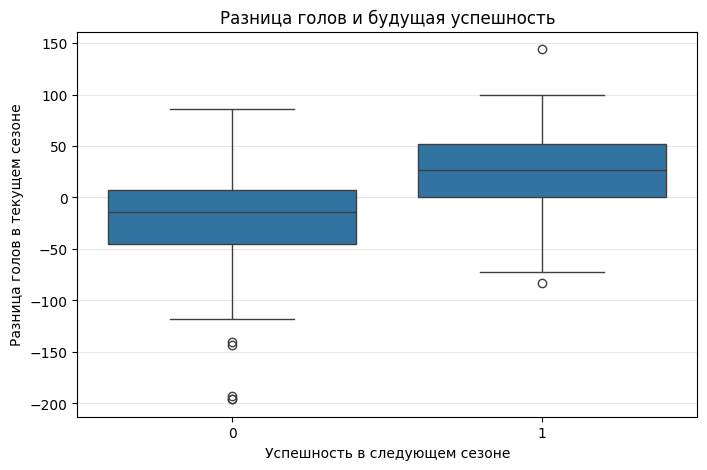


Корреляция goal_diff и target: 0.461

Доля успешных команд по группам goal_diff:


,count,mean
goal_diff_group,,
< -30,79,0.189873
-30–0,79,0.354430
0–30,85,0.517647
> 30,95,0.831579


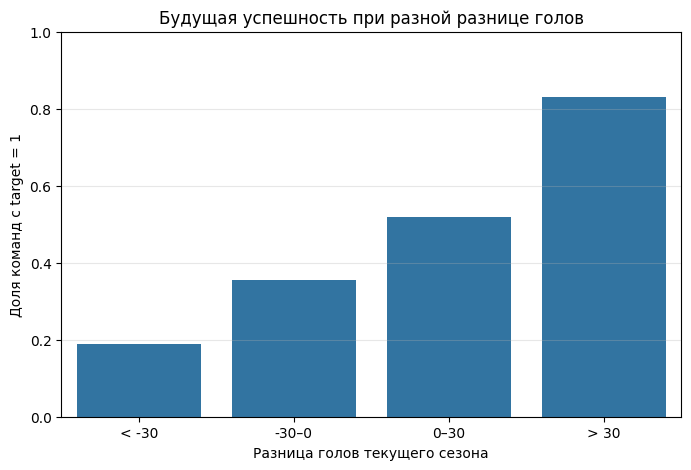


Пример для гипотезы 2:


,team,year,target_year,goal_diff,future_win_rate,future_median,target
7,Los Angeles Kings,1990,1991,86,0.438,0.444,0


In [70]:
# 3.2. Ваш код
# Добавьте ячейки при необходимости.
import matplotlib.pyplot as plt
import seaborn as sns

#Для 1 гипотезы
eda = train.copy()
print("Размер обучающей выборки:", eda.shape)
win_rate_stats = eda.groupby("target")["win_rate"].agg(["count", "mean", "median", "std"])
plt.figure(figsize=(8, 5))
sns.boxplot(data=eda,x="target",y="win_rate")

display(win_rate_stats)
plt.title("Доля побед в текущем сезоне и будущая успешность")
plt.xlabel("Успешность в следующем сезоне (target)")
plt.ylabel("Доля побед в текущем сезоне (win_rate)")
plt.grid(axis="y", alpha=0.3)
plt.show()

#Конкретное наблюдение
example_win = (
    eda[eda["target"] == 0]
    .sort_values("win_rate", ascending=False)
    .head(1)
)
print("\nПример для гипотезы 1:")
display(example_win[["team", "year", "target_year","win_rate", "future_win_rate","future_median", "target"]])


#Для 2 гипотзеы
goal_diff_stats = eda.groupby("target")["goal_diff"].agg(["count", "mean", "median", "std"])
print("\nРазница голов")
display(goal_diff_stats)
plt.figure(figsize=(8, 5))
sns.boxplot(data=eda, x="target", y="goal_diff")

plt.title("Разница голов и будущая успешность")
plt.xlabel("Успешность в следующем сезоне")
plt.ylabel("Разница голов в текущем сезоне")
plt.grid(axis="y", alpha=0.3)
plt.show()

correlation = eda["goal_diff"].corr(eda["target"])
print(f"\nКорреляция goal_diff и target: {correlation:.3f}")


eda["goal_diff_group"] = pd.cut(
    eda["goal_diff"],
    bins=[-float("inf"), -30, 0, 30, float("inf")],
    labels=["< -30", "-30–0", "0–30", "> 30"]
)
goal_success = eda.groupby("goal_diff_group",observed=True)["target"].agg(["count", "mean"])
print("\nДоля успешных команд по группам goal_diff:")
display(goal_success)
plt.figure(figsize=(8, 5))
sns.barplot(data=goal_success.reset_index(), x="goal_diff_group", y="mean")

plt.title("Будущая успешность при разной разнице голов")
plt.xlabel("Разница голов текущего сезона")
plt.ylabel("Доля команд с target = 1")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.show()

#Конкретное наблюдение
example_goals = (
    eda[eda["target"] == 0]
    .sort_values("goal_diff", ascending=False)
    .head(1)
)

print("\nПример для гипотезы 2:")
display(example_goals[
        ["team", "year", "target_year",
         "goal_diff", "future_win_rate",
         "future_median", "target"]
    ]
)


**Ответ 3.2:**

Для проверки **гипотезы 1** были рассчитаны описательные статистики `win_rate` отдельно для классов `target = 0` и `target = 1`, а также построена диаграмма размаха. Средняя доля побед для команд с `target = 1` составила 0.485, а для команд с `target = 0` = 0.387. Медианные значения также различаются: 0.4875 и 0.3915 соответственно. Таким образом, команды, оказавшиеся успешными в следующем сезоне, в среднем показывали более высокую долю побед в текущем сезоне. Полученные результаты согласуются с нашей гипотезой, но распределние двух классов пересекаются. Поэтому win_rate можно рассматривать как потенциально полезный признак для модели, однако его прогнозную ценность необходимо дополнительно проверить на валидационной\тестовых данных. (Пример New York Rangers в 1991 году имела win_rate = 0.625, но в следующем сезоне получила target = 0.)

Анализ для **гипотезы 2** показал положительную связь между разницей голов в текущем сезоне и успешностью команды в следующем. Корреляция между goal_diff и target составила 0.461. Средняя разница голов у команд с target = 1 составила +23.23, а у команд с target = 0 — −22.33.  Доля успешных команд увеличивается с ростом разницы голов: от 19% при goal_diff ниже −30 до 83% при значении выше +30.Однако существуют исключения, например: Los Angeles Kings в 1990 году имела goal_diff = +86, но получила target = 0 в следующем сезоне.
Таким образом, езультаты согласуются с гипотезой о положительной связи между goal_diff и будущей успешностью, но не доказывают причинную зависимость или точность будущих прогнозов.

## Раздел 4. Модели и эксперименты: 25 баллов

### 4.1. Постройте ориентиры

На train обучите простой константный baseline и оцените его на validation.
Отдельно используйте текущий `win_rate` как простую оценку для ранжирования
будущего класса. Посчитайте ROC-AUC обоих ориентиров и объясните,
какую планку задаёт каждый из них для обучаемой модели.

In [73]:
# 4.1. Ваш код
# Добавьте ячейки при необходимости.
import numpy as np
from sklearn.metrics import roc_auc_score
constant_score = train["target"].mean()
constant_predictions = np.full(len(val), constant_score)
auc_constant = roc_auc_score(val["target"], constant_predictions)

win_rate_predictions = val["win_rate"]
auc_win_rate = roc_auc_score(val["target"],win_rate_predictions)

results_41 = pd.DataFrame({
    "Ориентир": ["Константный", "Текущий win_rate"],
    "ROC-AUC": [auc_constant, auc_win_rate]
})

print("ROC-AUC baseline по win_rate:", round(auc_win_rate, 3))
print("Доля класса 1 на train:", round(constant_score, 3))
print("ROC-AUC константного baseline:", round(auc_constant, 3))
display(results_41)

ROC-AUC baseline по win_rate: 0.757
Доля класса 1 на train: 0.491
ROC-AUC константного baseline: 0.5


,Ориентир,ROC-AUC
0,Константный,0.500000
1,Текущий win_rate,0.756839


**Ответ 4.1:**

_Ваш ответ со ссылками на результаты собственной работы._

### 4.2. Постройте первую модель

Обучите логистическую регрессию. Самостоятельно выберите признаки и обоснуйте выбор.
Обработку пропусков и масштабирование включите в Pipeline и обучайте только на train.
Посчитайте ROC-AUC на validation и сравните с обоими ориентирами.
Объясните результат без использования test.

In [74]:
# 4.2. Ваш код
# Добавьте ячейки при необходимости.
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

features = ["win_rate", "goal_diff"]

X_train = train[features]
y_train = train["target"]

X_val = val[features]
y_val = val["target"]

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)
val_proba = model.predict_proba(X_val)[:, 1]
auc_model = roc_auc_score(y_val, val_proba)
comparison = pd.DataFrame({
    "Модель": [
        "Константный baseline",
        "Текущий win_rate",
        "Логистическая регрессия"
    ],  "ROC-AUC": [
         auc_constant,
         auc_win_rate,
         auc_model
    ]
})

display(comparison)

,Модель,ROC-AUC
0,Константный baseline,0.500000
1,Текущий win_rate,0.756839
2,Логистическая регрессия,0.772036


**Ответ 4.2:**

Для прогнозирования успешности команды была обучена логистическая регрессия с признаками win_rate и goal_diff

Для обработки пропусков использовался SimpleImputer с заполнением медианой, а для масштабирования признаков StandardScaler. Все этапы объединены в Pipeline и обучались только на тренировочной выборке.

На validation модель показала **ROC-AUC = 0.772**, превысив константный baseline (0.500) и ориентир по текущему win_rate (0.757).

Результат указывает на потенциальную пользу совместного использования двух признаков. Однако улучшение небольшое, поэтому его устойчивость ещё необходимо проверить. Тестовая выборка на данном этапе не использовалась.

### 4.3. Проведите собственный эксперимент

Выберите одно осмысленное изменение: состав признаков, способ обработки данных,
параметры или другой алгоритм. До запуска запишите ожидаемый эффект и его причину.
Изменяйте одну понятную часть решения, сравните варианты на validation
и зафиксируйте выбор финальной модели до просмотра test.
Дополнительные эксперименты допустимы, но их количество само по себе не оценивается.

In [75]:
# 4.3. Ваш код
# Добавьте ячейки при необходимости.
features_single = ["win_rate"]

model_single = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_single.fit(train[features_single], train["target"])
single_proba = model_single.predict_proba(val[features_single])[:, 1]
auc_single = roc_auc_score(val["target"], single_proba)

experiment_results = pd.DataFrame({
    "Признаки": [
        "win_rate",
        "win_rate + goal_diff"
    ], "ROC-AUC": [
        auc_single,
        auc_model
    ]
})

experiment_results["Разница с моделью из 4.2"] = (
    experiment_results["ROC-AUC"] - auc_model
)

display(experiment_results)

,Признаки,ROC-AUC,Разница с моделью из 4.2
0,win_rate,0.756839,-0.015198
1,win_rate + goal_diff,0.772036,0.000000


**Ответ 4.3:**

Для оценки влияния признака `goal_diff` были обучены две логистические регрессии с одинаковыми настройками: 1ая использовала только `win_rate`, 2ая `win_rate` и `goal_diff`.

На validation первая модель показала ROC-AUC = 0.757, вторая- 0.772. Добавление `goal_diff` улучшило результат на 0.015.

Таким образом, эксперимент показал что `goal_diff` содержит дополнительную полезную информацию для прогнозирования. Для дальнейшей оценки выбрана модель с двумя признаками, поскольку она показала лучший результат на validation.

При этом улучшение небольшое, поэтому его устойчивость необходимо проверить на тестовой выборке.

## Раздел 5. Итоговая оценка и анализ ошибок: 15 баллов

### 5.1. Проведите итоговую оценку

Зафиксируйте выбранную модель, признаки и параметры, затем один раз оцените её на test.
Покажите ROC-AUC, F1 и accuracy при пороге 0.5 для выбранной модели
и сопоставимых baseline. Объясните различия между метриками и сравните
результаты validation и test. После этого не меняйте выбранное решение.

In [78]:
# 5.1. Ваш код
# Добавьте ячейки при необходимости.

from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

features = ["win_rate", "goal_diff"]

def evaluate_model(y_true, scores):
    predictions = (np.asarray(scores) >= 0.5).astype(int)

    return {
        "ROC-AUC": roc_auc_score(y_true, scores),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Accuracy": accuracy_score(y_true, predictions)
        }

print("Финальная модель:", model.named_steps["classifier"])
print("Признаки:", features)
print("Обработка данных:", model.named_steps["imputer"],
      model.named_steps["scaler"])

results = []

for name, dataset in [("Validation", val),("Test", test)]:
    y_true = dataset["target"]
    constant_scores = np.full(len(dataset), constant_score)

    win_rate_scores = dataset["win_rate"].to_numpy()
    model_scores = model.predict_proba(dataset[features])[:, 1]

    for model_name, scores in [("Константный baseline", constant_scores),
     ("Текущий win_rate", win_rate_scores),
      ("Логистическая регрессия", model_scores)
    ]:
        metrics = evaluate_model(y_true, scores)

        results.append({"Выборка": name, "Модель": model_name,**metrics})


results_51 = pd.DataFrame(results)

print("\nСравнение моделей:")
display(results_51.round(3))

model_results = results_51[results_51["Модель"] == "Логистическая регрессия"].set_index("Выборка")

print("\nРезультаты логистической регрессии:")
display(model_results[["ROC-AUC", "F1", "Accuracy"]].round(3))

auc_val = model_results.loc["Validation", "ROC-AUC"]
auc_test = model_results.loc["Test", "ROC-AUC"]

print(f"\nROC-AUC на Validation: {auc_val:.3f}")
print(f"ROC-AUC на Test: {auc_test:.3f}")
print(f"Разница Test - Validation: {auc_test - auc_val:+.3f}")


Финальная модель: LogisticRegression(max_iter=1000)
Признаки: ['win_rate', 'goal_diff']
Обработка данных: SimpleImputer(strategy='median') StandardScaler()

Сравнение моделей:


,Выборка,Модель,ROC-AUC,F1,Accuracy
0,Validation,Константный baseline,0.500,0.000,0.528
1,Validation,Текущий win_rate,0.757,0.729,0.708
2,Validation,Логистическая регрессия,0.772,0.750,0.708
3,Test,Константный baseline,0.500,0.000,0.528
4,Test,Текущий win_rate,0.740,0.652,0.640
5,Test,Логистическая регрессия,0.760,0.706,0.663



Результаты логистической регрессии:


,ROC-AUC,F1,Accuracy
Выборка,,,
Validation,0.772,0.750,0.708
Test,0.760,0.706,0.663



ROC-AUC на Validation: 0.772
ROC-AUC на Test: 0.760
Разница Test - Validation: -0.012


**Ответ 5.1:**

Для итоговой оценки выбрана логистическая регрессия с признаками `win_rate` и `goal_diff`. Подготовка данных выполнялась через `Pipeline`, обученный только на train. На тестовой выборке модель показала **ROC-AUC = 0.760, F1 = 0.706 и Accuracy = 0.663**. По ROC-AUC она превзошла константный baseline (0.500) и ориентир по текущему `win_rate` (0.740).

По сравнению с validation ROC-AUC снизился на 0.012, F1 на 0.044, Accuracy - на 0.045. Это говорит о некотором ухудшении результатов на более поздних сезонах, особенно при классификации с порогом 0.5.

ROC-AUC характеризует качество ранжирования команд, Accuracy  долю правильных классификаций, а F1 - баланс точности и полноты положительного класса.

В целом модель сохранила прогностическую полезность на тестовой выборке, однако её результаты не гарантируют такое же качество на новых сезонах.

### 5.2. Разберите ошибки

Выберите от трёх до пяти ошибок финальной модели по явно указанному принципу.
Это могут быть наиболее уверенные ошибки, отдельный тип ошибки или другой
обоснованный набор. Покажите идентификаторы строк, вероятности и значения,
необходимые для анализа. Найдите общие черты и различия; отделите факты
из таблицы от гипотез и назовите данные, нужные для проверки одной гипотезы.

In [ ]:
# 5.2. Ваш код
# Добавьте ячейки при необходимости.

**Ответ 5.2:**

_Ваш ответ со ссылками на результаты собственной работы._

## Раздел 6. Выводы и воспроизводимость: 5 баллов

### 6.1. Сформулируйте выводы

Сформулируйте основные выводы и ограничения работы со ссылками на свои графики,
строки и метрики. Опишите минимум два решения, которые вы изменили
или подтвердили после получения результатов. Назовите одно улучшение,
которое вы сознательно не стали выполнять, и объясните причину.
Убедитесь, что последовательность работы и финальные параметры можно воспроизвести.

In [ ]:
# 6.1. Ваш код
# Добавьте ячейки при необходимости.

**Ответ 6.1:**

_Ваш ответ со ссылками на результаты собственной работы._